# Joint vs R2D2M2 vs stated scales on simulated datasets

## 1. Motivation

TabDGP can draw a dataset's outcome from a Bayesian generalized linear mixed model (GLMM).<br>
It draws the model's priors and parameters per dataset.<br>
However, the default independent priors that are usually stated at inference time have an issue:<br>
They tend to make the linear predictor η grow with every term, which saturates the link functions and raises R² to near 1.<br>
TabDGP therefore draws the prior scales jointly with a budget for the variance of η.<br>
The R2D2M2 prior (the R²-induced Dirichlet decomposition for multilevel models; Aguilar & Bürkner, 2023) also spends a budget to prevent R² saturation.

This experiment checks how increasing the number of columns (d), grouping factors (f), and random effects (q) affects var(η) and the explained variance.

**Contents**
1. Motivation
2. Model
3. Measures: variance partition, noise on the links, saturation
4. Prior structures: stated, joint, R2D2M2
5. Simulated datasets
6. Curves
7. Light tails and saturation sources
8. Finding

References

## 2. Model

A GLMM ties the mean of y to the linear predictor η through a link function g, so that E[y] = μ(η) with μ = g⁻¹ the inverse link.<br>
Over a dataset's rows,

$$\eta = \beta_0 + X\beta + \sum_{k=1}^{f} Z_k \alpha_k$$

- **d:** the rank of the design matrix, the intercept included, so d = 1 is an intercept-only model.
- **X:** the $d-1$ design columns besides the intercept.
- **β₀ and β:** the intercept and the $d-1$ fixed slopes (together: the fixed effects).
- **Z_k:** grouping factor k's q columns, a column of ones for the random intercept and $q - 1$ of X's columns for the random slopes.
- **α_k:** factor k's random effects, q per group, drawn from N(0, Σ_k), and each row takes its own group's.
- **Σ_k:** their covariance, built from their standard deviations (sds) σ_α and a correlation matrix.
- **y's family:** Gaussian with residual sd σ_ε (identity link), Bernoulli (logit link) or Poisson (log link).

Each parameter's prior has a family and a prior scale, both drawn per dataset.
- **Intercept β₀:** prior location ν₀ ~ Uniform(−3, 3) and prior scale ~ LogUniform(0.1, 10).
- **Families:** Normal, Student-t or Cauchy for β, and half-normal, exponential, half-Student-t or half-Cauchy for σ_α and σ_ε.
- **Prior scales:** of β, σ_α and σ_ε, set by the prior structure (section 4).

## 3. Measures

Every measure is computed from the drawn parameters (not from a fit).

### Variance partition

R² compares the variance of η with y's noise around η, so both are taken on η's scale, the link scale.<br>
y's variance on that scale splits into a fixed part, a part per grouping factor and noise (Nakagawa et al., 2017):

$$\sigma^2_\text{total} = \sigma^2_\text{fixed} + \sum_k \sigma^2_k + \sigma^2_\text{noise}$$

- **$\sigma^2_\text{fixed}$:** the variance of Xβ over the rows.
- **$\sigma^2_k$:** grouping factor k's variance, σ_α² for a lone random intercept and z'Σ_k z averaged over the rows with random slopes (Johnson, 2014).
- **$\sigma^2_\text{noise}$:** y's noise around η, σ_ε² for Gaussian y and a stand-in on the logit and log links (next subsection).

The fixed and random parts add up to var(η), the variance η explains.<br>
The measures are ratios of these parts:
- **Marginal $R^2_m$:** $\sigma^2_\text{fixed} / \sigma^2_\text{total}$, the share of variance the fixed effects explain.
- **Conditional $R^2_c$:** $(\sigma^2_\text{fixed} + \sum_k \sigma^2_k) / \sigma^2_\text{total}$, the share the fixed and random effects explain together.
- **Fixed share:** $R^2_m / R^2_c$, the fixed effects' part of the explained variance.
- **Intraclass correlation (ICC):** $\sigma^2_k / \sigma^2_\text{total}$, each grouping factor's share of the variance.

### Noise on the links

A Gaussian y has its residual on η's scale, but a Bernoulli or Poisson y has none, so the partition charges a stand-in.<br>
On the logit link, y = 1 when η plus a logistic noise is positive, and that noise has a variance of π²/3 ≈ 3.3.<br>
On the log link, a count with mean λ has a variance of about 1/λ in logs, so large counts carry little noise.<br>
The partition charges ln(1 + 1/λ) there, with λ the mean rate over the rows.<br>
So the same var(η) explains much less on the logit link than on the log link.<br>
At var(η) = 1, $R^2_c$ is 1 / (1 + 3.3) = 0.23 on the logit link and 1 / (1 + 0.1) = 0.91 on the log link at λ = 10.

### Saturation

A link saturates when η runs so far that y nearly loses its noise.<br>
On the logit link, that is some |η| > 10, where P(y = 1) lies within 5 × 10⁻⁵ of 0 or 1.<br>
On the log link, it is some Poisson rate above 10⁶.<br>
Saturation is the share of datasets that saturate.<br>
A Gaussian y never saturates, since its link is the identity.

## 4. Prior structures

The experiment compares three prior structures.<br>
They differ only in the prior scales of the fixed effects β, of the random effects' sds σ_α and, for a Gaussian y, of the residual sd σ_ε, and so in how they constrain var(η):

| prior structure | constraint | behavior as d, f, q grow |
|---|---|---|
| stated | none, priors are independent | var(η) grows with every term |
| joint | draw a budget τ² = var(η), split it between fixed and random effects by φ | var(η) ≈ the budget, split by ≈ φ |
| R2D2M2 | draw R² and set var(η) = $\tilde\sigma^2$ R² / (1 − R²) | var(η) ≈ the budget, but the fixed share is (d − 1) / (d − 1 + Σ_k q_k) on average |

### Stated

A stated prior is what a user writes into a model before seeing the data: one prior scale for the fixed effects, one for σ_α and one for σ_ε, whatever d, f and q are.<br>
The experiment runs it in two versions:
- **Survey (`survey`):** one published model's prior scales per dataset, drawn from a survey of published models.
- **Unit (`unit`):** a prior scale of 1 for every coefficient, which needs no survey to rerun.

Note: A scale of 2.5 everywhere, rstanarm's default for the fixed effects (Goodrich et al., 2025), would multiply var(η) by 6.25 and saturate sooner.

### Joint

- **Budget:** τ² = R² ~ Beta(2, 2) for Gaussian y, otherwise τ ~ LogUniform(0.25, 4).
- **σ_ε's prior scale:** √(1 − R²) for Gaussian y.
- **Fixed effects share:** φ ~ Beta(1, 1) of the budget.
- **Random effects share:** τ²(1 − φ), i.e. the rest of the budget, further split among grouping factors by a Dirichlet(1).
- **Prior scales:** each with probability 0.5
    - constrained to be equal within the fixed effects and within each grouping factor, or
    - spread by weights: log w_j ~ N(0, c²) and c ~ Uniform(0, 2).

### R2D2M2

- **R²:** drawn from Beta(2, 2).
- **$\tilde\sigma^2$:** R2D2M2's stand-in for $\sigma^2_\text{noise}$, Var(y | η) / μ'(η)² at η = ν₀, the intercept's prior location (Yanchenko et al., 2025).
- **$\tilde\sigma^2$ by family:** 1 − R² for Gaussian y, 1 / [μ₀ (1 − μ₀)] with μ₀ = μ(ν₀) on the logit link, exp(−ν₀) on the log link.
- **Split:** one Dirichlet(a) of the budget among all d − 1 fixed slopes and Σ_k q_k random effects.
- **Concentration:** a = 0.5 (`r2d2m2-0.5`) or a = 1 (`r2d2m2-1`).

Note: Our prior families are partly heavy-tailed, whereas R2D2M2's paper draws every effect from a Normal at its scale.

## 5. Simulated datasets

The experiment varies one size at a time.<br>
Each value is a cell, and TabDGP draws all other sizes from its defaults for grouped tables.
- **Rank d:** 1, 2, 4, 8, 16 or 32, with at least 64 rows (2d at d = 32).
- **Grouping factors f:** 1, 2 or 3.
- **Random effects per factor q:** 1, 3 or 6, the random intercept included, with d of at least 6 so that 6 fit.
- **y's families:** all three on every dataset's covariates.
- **Arms:** the five priors of section 4, `joint`, `r2d2m2-0.5`, `r2d2m2-1`, `survey` and `unit`, each on the same covariates.
- **Datasets:** 1,000 per cell and family.
- **Light tails:** a second run that draws only a Normal β and a half-normal σ_α, the families the budgets assume, close to R2D2M2's paper.

`simulated.py` draws the datasets in about 100 s per run and writes `simulated.csv.gz`, or `simulated-light.csv.gz` under light tails, which this notebook reads.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

records = pd.read_csv('simulated.csv.gz')
light_records = pd.read_csv('simulated-light.csv.gz')  # Normal β and half-normal σ_α only
print(f'{len(records)} records per run, {records["index"].nunique()} datasets per cell')

180000 records per run, 1000 datasets per cell


## 6. Curves

Each line is an arm's median over a cell's datasets, and its band spans the 10th to 90th percentiles.<br>
The saturated share has no band, since it is one number per cell.<br>
The curves show the default tails, and the light-tailed run enters only the tables below.

In [2]:
MEASURES = {
    'saturated': 'saturated share',
    'r2_marginal': '$R^2_m$',
    'r2_conditional': '$R^2_c$',
    'fixed_share': '$R^2_m / R^2_c$',
    'icc_1': 'ICC of factor 1',
    'icc_2': 'ICC of factor 2',
    'icc_3': 'ICC of factor 3',
}
FIELD_LABELS = {
    'rank': 'd (rank of the design matrix)',
    'factors': 'f (grouping factors)',
    'random_effects': 'q (random effects per factor)',
}
# three hues (joint, R2D2M2, stated), a dashed line for each one's second variant
ARM_STYLES = {
    'joint': {'color': '#2a78d6', 'linestyle': '-'},
    'r2d2m2-0.5': {'color': '#eb6834', 'linestyle': '-'},
    'r2d2m2-1': {'color': '#eb6834', 'linestyle': '--'},
    'survey': {'color': '#1baf7a', 'linestyle': '-'},
    'unit': {'color': '#1baf7a', 'linestyle': '--'},
}


def plotCurves(records: pd.DataFrame, family: str) -> None:
    """One family's measures over each swept size, saved as simulated-<family>.pdf."""
    table = records[records['family'] == family]
    fields = table['field'].unique()  # the swept sizes, in the order simulated.py sweeps them
    measures = []
    for measure in MEASURES:
        if table[measure].notna().any():  # a Gaussian y never saturates
            measures.append(measure)
    figure, axes = plt.subplots(
        len(measures),
        len(fields),
        figsize=(11, 2.1 * len(measures)),
        sharey='row',
        squeeze=False,
        layout='constrained',
    )
    for row, measure in enumerate(measures):
        banded = measure != 'saturated'  # a share of datasets has no band
        for column, field in enumerate(fields):
            ax = axes[row, column]
            swept = table[table['field'] == field]
            values = sorted(swept['value'].unique())
            cells = swept.groupby(['arm', 'value'])[measure]
            if banded:
                center = cells.median()
                low = cells.quantile(0.1)
                high = cells.quantile(0.9)
            else:
                center = cells.mean()
            for arm in table['arm'].unique():
                style = ARM_STYLES[arm]
                # a marker per cell, so a measure with one cell (a third factor's ICC) shows
                ax.plot(center[arm], **style, label=arm, linewidth=2, marker='o', markersize=4)
                if banded:
                    color = style['color']
                    ax.fill_between(low[arm].index, low[arm], high[arm], color=color, alpha=0.12)
            if field == 'rank':
                ax.set_xscale('log', base=2)
                ax.set_xticks(values, [str(value) for value in values])
            else:
                ax.set_xticks(values)
            ax.tick_params(labelleft=True)  # each panel's own y values, though a row shares them
            ax.grid(color='#e4e3df', linewidth=0.6)
            ax.spines[['top', 'right']].set_visible(False)
            if row == len(measures) - 1:
                ax.set_xlabel(FIELD_LABELS[field])
            if column == 0:
                ax.set_ylabel(MEASURES[measure])
    handles, labels = axes[0, 0].get_legend_handles_labels()
    figure.legend(handles, labels, loc='outside lower center', ncol=len(labels), frameon=False)
    figure.suptitle(f'{family} y')
    figure.savefig(f'simulated-{family}.pdf', metadata={'CreationDate': None})

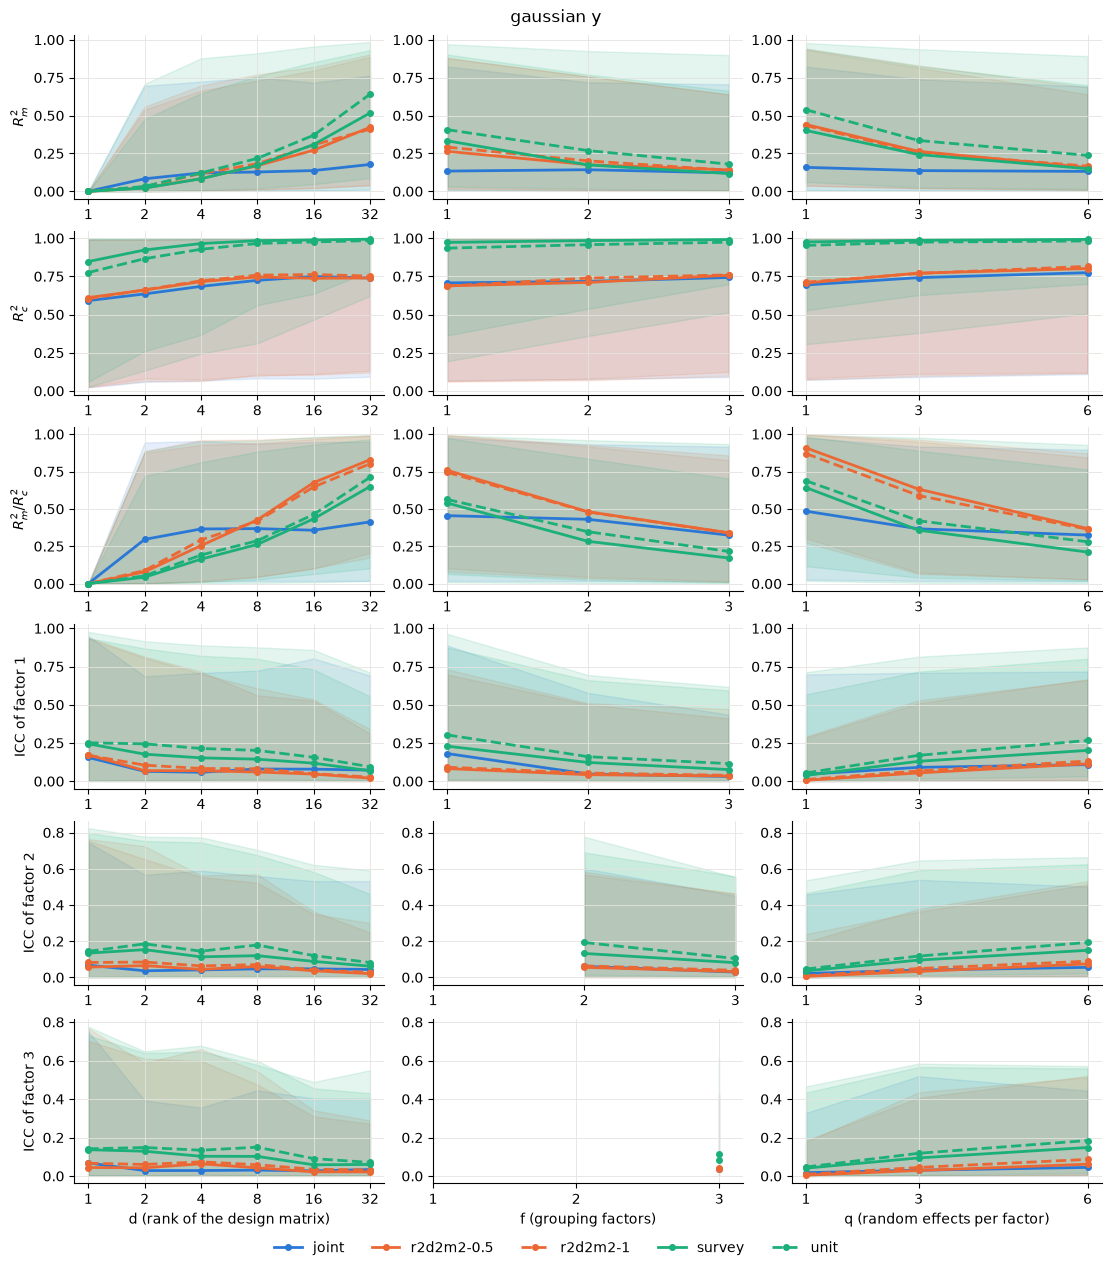

In [3]:
plotCurves(records, 'gaussian')

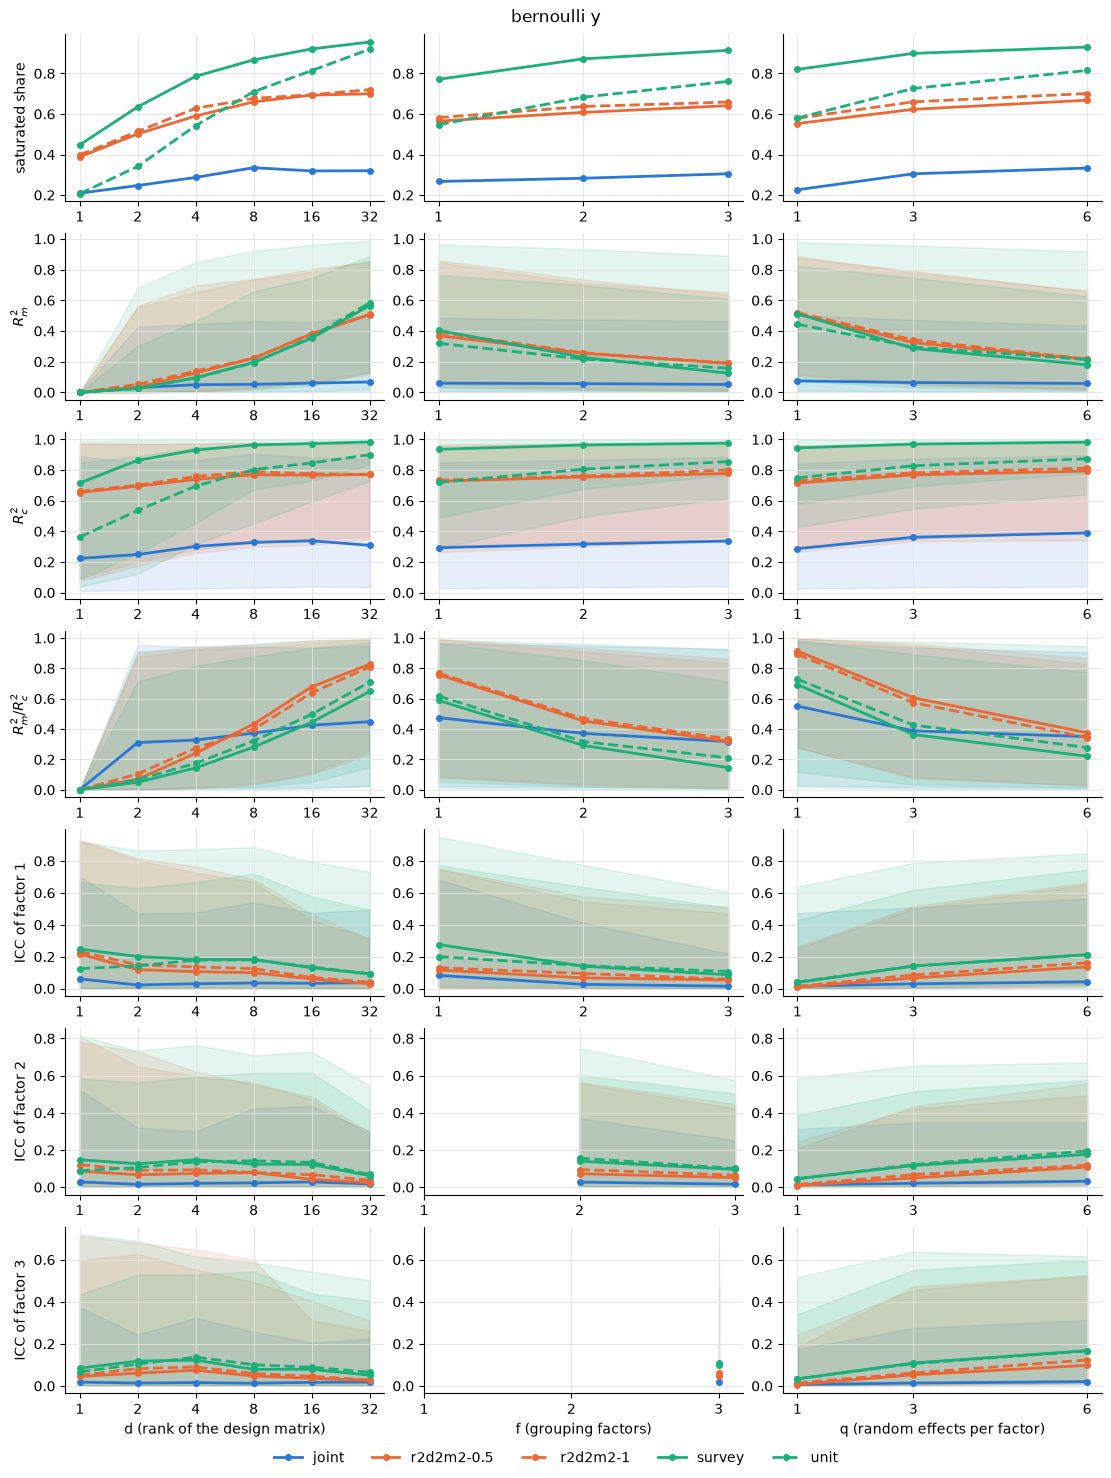

In [4]:
plotCurves(records, 'bernoulli')

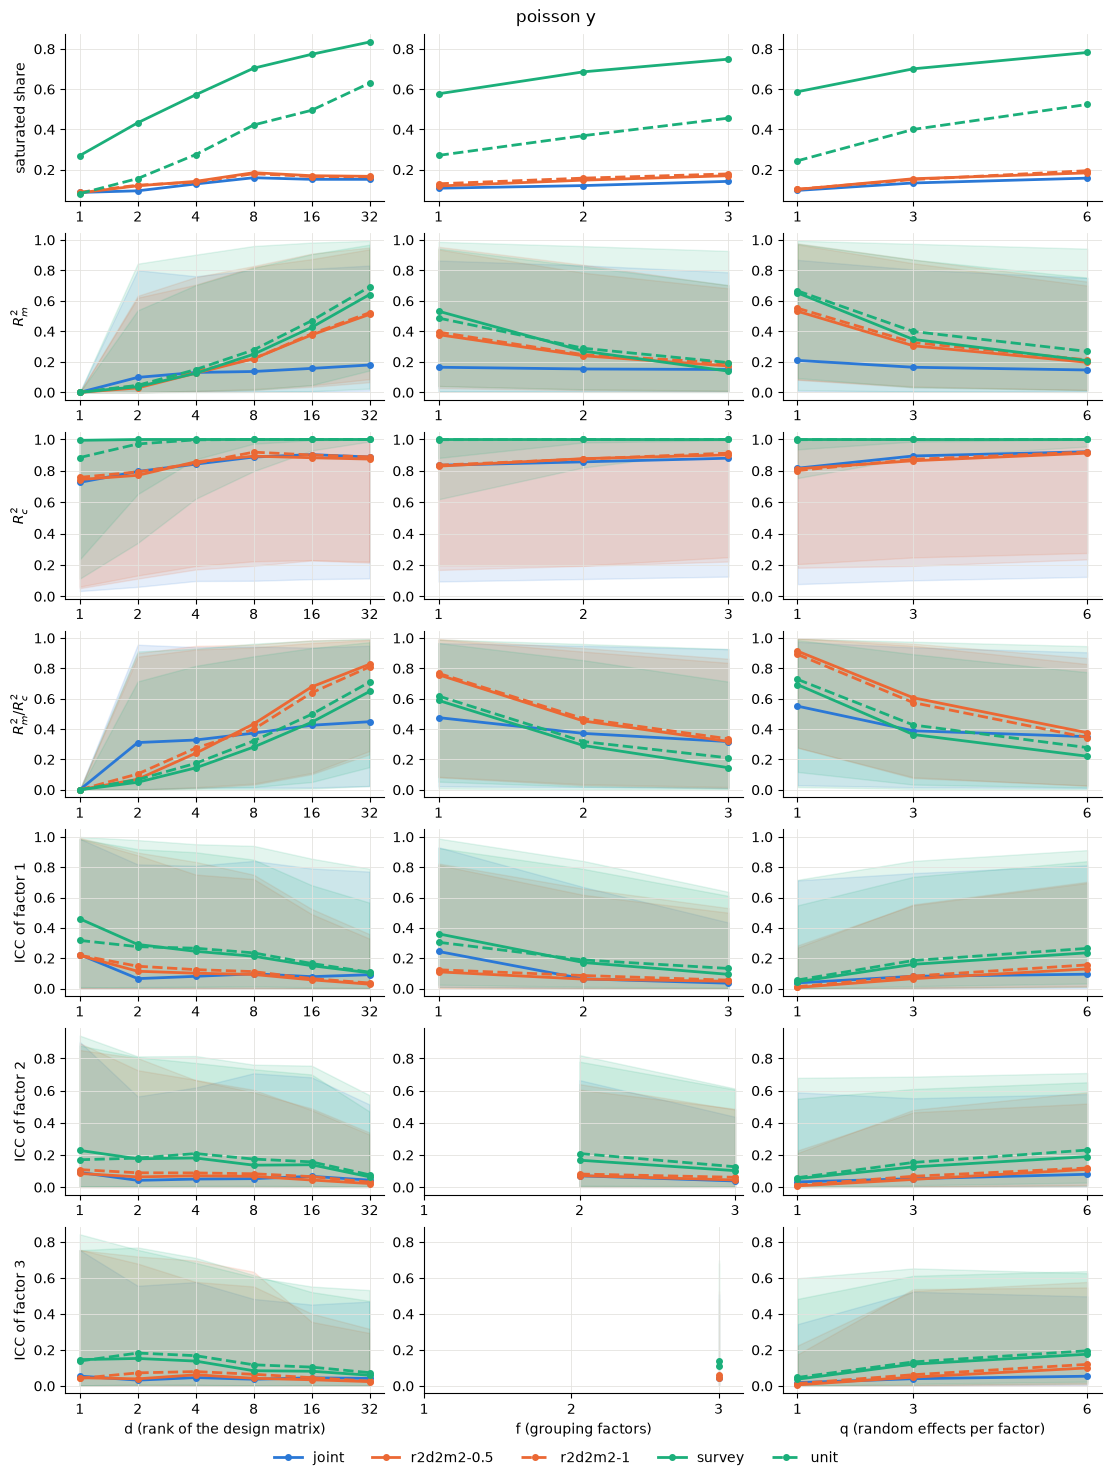

In [5]:
plotCurves(records, 'poisson')

## 7. Light tails and saturation sources

The curves show neither the light-tailed run nor where saturation comes from, so these tables add both.

In [6]:
runs = {'default': records, 'light': light_records}

# the joint prior's fixed share on a Gaussian y, its median per cell, under either tails
shares = {}
for run, table in runs.items():
    joint = table[(table['arm'] == 'joint') & (table['family'] == 'gaussian')]
    shares[run] = joint.groupby(['field', 'value'], sort=False)['fixed_share'].median()
print(pd.DataFrame(shares).round(2).to_string())

                      default  light
field          value                
rank           1         0.00   0.00
               2         0.30   0.41
               4         0.37   0.48
               8         0.37   0.50
               16        0.36   0.54
               32        0.41   0.55
factors        1         0.45   0.53
               2         0.43   0.51
               3         0.32   0.48
random_effects 1         0.48   0.59
               3         0.37   0.52
               6         0.32   0.47


In [7]:
# each arm's logit saturation and median R²_c on a Gaussian y, over all cells, under either tails
summary = {}
for run, table in runs.items():
    arms = table.groupby(['family', 'arm'])
    summary[(run, 'logit saturated')] = arms['saturated'].mean()['bernoulli']
    summary[(run, 'Gaussian R²_c')] = arms['r2_conditional'].median()['gaussian']
print(pd.DataFrame(summary).round(2).to_string())

                   default                         light              
           logit saturated Gaussian R²_c logit saturated Gaussian R²_c
arm                                                                   
joint                 0.29          0.71            0.18          0.57
r2d2m2-0.5            0.60          0.72            0.50          0.60
r2d2m2-1              0.62          0.73            0.52          0.60
survey                0.82          0.98            0.76          0.96
unit                  0.64          0.96            0.51          0.92


In [8]:
# each source of the logit's saturation under the joint prior and the default tails:
# how often the prior draws it, how often it saturates and what it adds to the saturated share
logit = records[(records['arm'] == 'joint') & (records['family'] == 'bernoulli')]
saturated = logit['saturated']
sources = {
    'τ > 2': logit['predictor_sd'] > 2,
    '|β₀| > 10': logit['intercept'].abs() > 10,
}
for family in sorted(logit['sigma_alpha_family'].unique()):
    sources[f'σ_α {family}'] = logit['sigma_alpha_family'] == family
for family in sorted(logit['beta_family'].unique()):
    sources[f'β {family}'] = logit['beta_family'] == family
rows = {}
for source, drawn in sources.items():
    rows[source] = {
        'drawn': drawn.mean(),
        'saturated': saturated[drawn].mean(),
        'adds': saturated.mean() - saturated[~drawn].mean(),
    }
print(pd.DataFrame(rows).T.round(2).to_string())

                    drawn  saturated  adds
τ > 2                0.26       0.59  0.10
|β₀| > 10            0.05       1.00  0.04
σ_α exponential      0.25       0.25 -0.01
σ_α half_cauchy      0.26       0.44  0.05
σ_α half_normal      0.25       0.21 -0.03
σ_α half_student_t   0.24       0.24 -0.01
β cauchy             0.02       0.64  0.01
β normal             0.68       0.26 -0.06
β student_t          0.30       0.33  0.02


## 8. Finding

### Only the joint prior keeps $R^2_m$ and saturation flat over d

- **Joint $R^2_m$:** at most 0.2 at every d.
- **Joint saturation:** 21-34 % on the logit link, 9-16 % on the log link.
- **R2D2M2's fixed share:** set by the number of terms, from about 0.1 at d = 2 to 0.8 at d = 33.
- **R2D2M2 at q = 1:** random intercepts that explain almost nothing.
- **R2D2M2's logit saturation:** 39-72 %, about twice the joint's under either tails.
- **Its cause:** a $\tilde\sigma^2$ of at least 4 on the logit link, above the π²/3 the partition charges.
- **Stated priors:** more saturation with every column, over 95 % on the logit link at d = 32.
- **R2D2M2's concentration:** barely matters.

### The budget holds only on average

A dataset draws its effects once, so each part of var(η) meets its budget only on average.<br>
A part with few terms tends to fall short, and a heavy-tailed part with many terms to overshoot.
- **Fixed share:** leans toward the part with more terms, rising over d and falling over f and q.
- **The lean:** small next to the spread of φ's Beta(1, 1).
- **Under light tails:** the lean over d and q stays, the fall over f mostly goes (section 7).
- **Heavy tails:** a lower fixed share in every cell with a slope, as σ_α's families are heavier than β's.
- **Gaussian $R^2_c$:** above its budget's median of 0.5, as σ_ε is a part with one term.

### Verdict

| goal | joint prior |
|---|---|
| a partition that ignores d, f and q, unless real tables show otherwise | met by its budget |
| each dataset's partition close to its drawn split | missed, through the number of terms and the tails |
| the partition's levels of real grouped tables, per link | open until the [comparison with real tables](https://github.com/adkipnis/tabdgp/issues/77) |
| rare saturation | missed on the logit link |

The joint prior stays, as the only one to meet the first goal.<br>
Four of its defaults set its levels, and the comparison with real tables decides which of them to move.
- **τ's upper end:** 4 on the links, the main source of the logit's saturation.
- **The intercept's prior scale:** up to 10, and any |β₀| > 10 saturates the logit.
- **The tails' shares:** three quarters heavy-tailed σ_α, worth about 10 points of the logit's saturation.
- **R² instead of τ on the links:** τ² = π²/3 · R² / (1 − R²), which centers the logit's $R^2_c$ near 0.5 but saturates more.

τ's upper end and R² are one knob seen from two sides, so only one of them moves.<br>
Rescaling the heavy-tailed families can at best reach the light-tailed run.

## References

Aguilar, J. E., & Bürkner, P.-C. (2023). Intuitive joint priors for Bayesian linear multilevel models: The R2D2M2 prior. *Electronic Journal of Statistics*, *17*(1), 1711-1767. https://doi.org/10.1214/23-EJS2136

Goodrich, B., Gabry, J., Ali, I., & Brilleman, S. (2025). *rstanarm: Bayesian applied regression modeling via Stan* (R package version 2.32.2) [Computer software]. https://mc-stan.org/rstanarm/

Johnson, P. C. D. (2014). Extension of Nakagawa & Schielzeth's R²GLMM to random slopes models. *Methods in Ecology and Evolution*, *5*(9), 944-946. https://doi.org/10.1111/2041-210X.12225

Nakagawa, S., Johnson, P. C. D., & Schielzeth, H. (2017). The coefficient of determination R² and intra-class correlation coefficient from generalized linear mixed-effects models revisited and expanded. *Journal of the Royal Society Interface*, *14*(134), 20170213. https://doi.org/10.1098/rsif.2017.0213

Yanchenko, E., Bondell, H. D., & Reich, B. J. (2025). The R2D2 prior for generalized linear mixed models. *The American Statistician*, *79*(1), 40-49. https://doi.org/10.1080/00031305.2024.2352010